# Una red neuronal simple

En este notebook construyes y entrenas tu primera red neuronal con PyTorch, paso a paso y sin saltarse nada.

**El problema.** Eres repartidor en bicicleta y te llega un pedido a **7 millas**. La empresa promete entregar en menos de **30 minutos**, y otra entrega tarde te puede costar el trabajo. ¿Aceptas el pedido? En lugar de adivinar, vas a entrenar un modelo con tus entregas anteriores para que estime cuánto te vas a demorar.

Seguimos el recorrido habitual de un proyecto de machine learning:

1. **Preparar** los datos: distancias y tiempos de entregas pasadas.
2. **Construir** el modelo: primero una sola neurona.
3. **Entrenar**: que el modelo encuentre la relación entre distancia y tiempo.
4. **Predecir**: estimar el tiempo del pedido de 7 millas.

Después complicamos el problema hasta que una neurona ya no alcanza, y ahí armamos una red con una capa oculta.

**Contenido**

1. Preparación
2. Los datos
3. El modelo: una neurona
4. Función de pérdida y optimizador
5. El ciclo de entrenamiento
6. Predecir y decidir
7. Qué aprendió el modelo
8. Cuando una neurona no alcanza
9. Normalizar los datos
10. Una red con capa oculta
11. Por qué hace falta la activación
12. Resumen y ejercicios

Si nunca has usado tensores ni `autograd`, pasa antes por `00-fundamentos`.

## 1. Preparación

- `torch` es la librería principal.
- `torch.nn` trae las piezas para armar redes: capas, activaciones y funciones de pérdida.
- `matplotlib` es para los gráficos.

La semilla fija los números aleatorios, así tus resultados coinciden con los de este notebook.

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Los datos

Tenemos diez entregas anteriores. De cada una sabemos la **distancia** en millas y el **tiempo** en minutos.

- La distancia es la **entrada** del modelo (también se le dice *característica* o *feature*).
- El tiempo es lo que queremos predecir (la *etiqueta* o *target*).

Dos detalles de forma que importan:

- Las capas de PyTorch esperan los datos como **[número de ejemplos, número de características]**. Tenemos 10 ejemplos y 1 característica, así que la forma es `[10, 1]`. Por eso cada valor va en su propio par de corchetes.
- Los parámetros de una red son `float32` por omisión, y los datos tienen que ser del mismo tipo.

In [2]:
distancias = torch.tensor([[1.0], [1.5], [2.0], [2.5], [3.0],
                           [3.5], [4.0], [4.5], [5.0], [5.5]], dtype=torch.float32)

tiempos = torch.tensor([[7.3], [9.1], [12.4], [14.2], [17.5],
                        [19.0], [22.6], [24.1], [27.4], [29.2]], dtype=torch.float32)

print("forma de las entradas :", distancias.shape, distancias.dtype)
print("forma de las etiquetas:", tiempos.shape, tiempos.dtype)

forma de las entradas : torch.Size([10, 1]) torch.float32
forma de las etiquetas: torch.Size([10, 1]) torch.float32


Antes de modelar conviene mirar los datos. Marcamos también el pedido que nos interesa (7 millas) y el límite de 30 minutos.

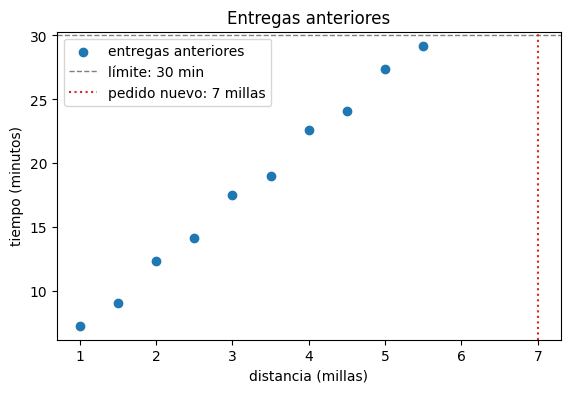

In [3]:
plt.figure(figsize=(6.5, 4))
plt.scatter(distancias, tiempos, label="entregas anteriores")
plt.axhline(30, color="gray", linestyle="--", linewidth=1, label="límite: 30 min")
plt.axvline(7, color="tab:red", linestyle=":", linewidth=1.5, label="pedido nuevo: 7 millas")
plt.xlabel("distancia (millas)")
plt.ylabel("tiempo (minutos)")
plt.title("Entregas anteriores")
plt.legend()
plt.show()

Los puntos caen casi sobre una recta: a más distancia, más tiempo, y en una proporción bastante constante. Eso sugiere un modelo de la forma

$$\text{tiempo} = w \cdot \text{distancia} + b$$

- $w$ (el **peso**) es cuántos minutos suma cada milla.
- $b$ (el **sesgo**) es el tiempo fijo que no depende de la distancia: retirar el pedido, estacionar, subir al departamento.

No conocemos ni $w$ ni $b$. Entrenar es encontrarlos a partir de los datos.

## 3. El modelo: una neurona

Una neurona con una entrada calcula exactamente $w x + b$. En PyTorch eso es `nn.Linear(1, 1)`: una capa con 1 entrada y 1 salida.

La envolvemos en `nn.Sequential`, un contenedor que aplica sus capas una tras otra. Con una sola capa no haría falta, pero así el paso a una red más grande (sección 10) será solo agregar líneas.

In [4]:
modelo = nn.Sequential(
    nn.Linear(in_features=1, out_features=1)
)

print(modelo)

Sequential(
  (0): Linear(in_features=1, out_features=1, bias=True)
)


`nn.Linear` crea sus parámetros con valores **aleatorios**. Todavía no sabe nada del problema:

In [5]:
for nombre, parametro in modelo.named_parameters():
    print(f"{nombre:9s} {parametro.data}")

with torch.no_grad():
    print("\nPredicción para 7 millas antes de entrenar:", round(modelo(torch.tensor([[7.0]])).item(), 2), "minutos")

0.weight  tensor([[0.7645]])
0.bias    tensor([0.8300])

Predicción para 7 millas antes de entrenar: 6.18 minutos


`0.weight` es $w$ y `0.bias` es $b$ (el `0` es la posición de la capa dentro del `Sequential`). La predicción no tiene sentido porque los parámetros salieron de un sorteo.

## 4. Función de pérdida y optimizador

Para mejorar, el modelo necesita dos cosas más.

**Una función de pérdida**: un número que mide qué tan mal predice. Usamos el **error cuadrático medio** (MSE):

$$L(w, b) = \frac{1}{N} \sum_{i=1}^{N} \left( \hat{y}_i - y_i \right)^2$$

donde $\hat{y}_i$ es la predicción y $y_i$ el tiempo real. Se eleva al cuadrado para que los errores no se cancelen entre sí y para castigar más los errores grandes. Si la pérdida vale 0, el modelo acierta todo.

**Un optimizador**: el encargado de modificar $w$ y $b$ para que la pérdida baje. Usamos `SGD` (descenso de gradiente), que mueve cada parámetro un poco en la dirección que reduce la pérdida. El tamaño de ese paso es la **tasa de aprendizaje** `lr`.

Por ahora basta con esa idea. El módulo `02-descenso-de-gradiente` está dedicado a cómo funciona por dentro.

In [6]:
criterio = nn.MSELoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.01)

`modelo.parameters()` le entrega al optimizador la lista de números que tiene permitido ajustar: aquí, $w$ y $b$.

## 5. El ciclo de entrenamiento

Entrenar es repetir muchas veces los mismos pasos. Cada repetición completa sobre los datos se llama **época**.

| Paso | Código | Qué hace |
|---|---|---|
| 1. Predicción | `prediccion = modelo(distancias)` | Calcula $\hat{y}$ con los parámetros actuales |
| 2. Pérdida | `perdida = criterio(prediccion, tiempos)` | Mide el error |
| 3. Limpiar | `optimizador.zero_grad()` | Borra los gradientes de la vuelta anterior |
| 4. Gradientes | `perdida.backward()` | Calcula cómo cambia la pérdida al mover cada parámetro |
| 5. Actualizar | `optimizador.step()` | Mueve los parámetros un paso |

El paso 3 existe porque PyTorch **acumula** los gradientes: si no los borras, los de esta vuelta se suman a los de la anterior y el modelo aprende mal sin dar ningún error.

In [7]:
epocas = 2000
historial = []

for epoca in range(epocas):
    prediccion = modelo(distancias)             # 1. Predicción
    perdida = criterio(prediccion, tiempos)     # 2. Pérdida

    optimizador.zero_grad()                     # 3. Limpiar gradientes
    perdida.backward()                          # 4. Gradientes
    optimizador.step()                          # 5. Actualizar

    historial.append(perdida.item())
    if epoca % 400 == 0 or epoca == epocas - 1:
        print(f"época {epoca:4d}   pérdida = {perdida.item():8.4f}")

época    0   pérdida = 260.6893
época  400   pérdida =   0.1752


época  800   pérdida =   0.1748
época 1200   pérdida =   0.1748


época 1600   pérdida =   0.1748
época 1999   pérdida =   0.1748


La pérdida parte alta y baja hasta estabilizarse. No llega a cero porque los datos no están exactamente sobre una recta: ninguna recta pasa por los diez puntos a la vez.

Graficar la pérdida es la primera herramienta de diagnóstico. Si no baja, algo anda mal (datos, forma de los tensores, tasa de aprendizaje).

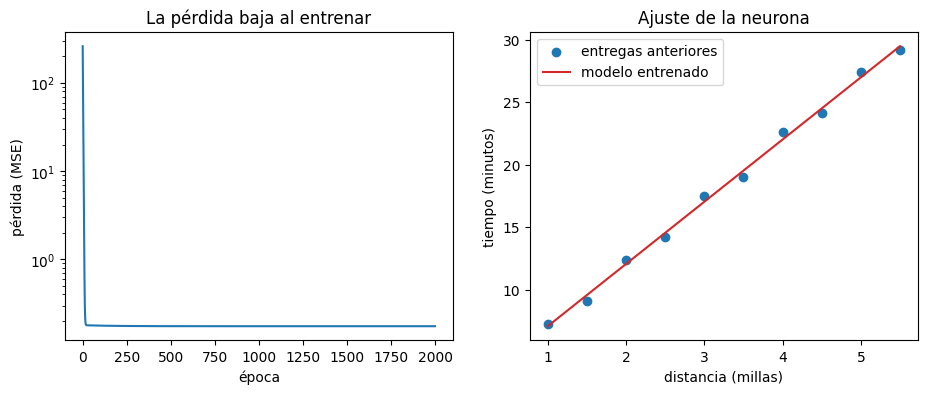

In [8]:
with torch.no_grad():
    recta = modelo(distancias)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(historial)
ejes[0].set_yscale("log")
ejes[0].set_xlabel("época")
ejes[0].set_ylabel("pérdida (MSE)")
ejes[0].set_title("La pérdida baja al entrenar")

ejes[1].scatter(distancias, tiempos, label="entregas anteriores")
ejes[1].plot(distancias, recta, color="tab:red", label="modelo entrenado")
ejes[1].set_xlabel("distancia (millas)")
ejes[1].set_ylabel("tiempo (minutos)")
ejes[1].set_title("Ajuste de la neurona")
ejes[1].legend()

plt.show()

El eje vertical de la pérdida está en escala logarítmica para que se vea la bajada completa, que al principio es muy brusca.

## 6. Predecir y decidir

Con el modelo entrenado respondemos la pregunta original. Usamos `torch.no_grad()` porque al predecir no hace falta calcular gradientes, y eso ahorra memoria y tiempo.

La entrada tiene que tener la misma forma que los datos de entrenamiento: `[ejemplos, características]`, o sea `[1, 1]`.

In [9]:
pedido = torch.tensor([[7.0]])

with torch.no_grad():
    minutos = modelo(pedido).item()

print(f"Tiempo estimado para 7 millas: {minutos:.1f} minutos")

if minutos < 30:
    print("Decisión: alcanzas. Acepta el pedido.")
else:
    print("Decisión: no alcanzas a llegar en 30 minutos. Mejor no lo aceptes.")

Tiempo estimado para 7 millas: 36.9 minutos
Decisión: no alcanzas a llegar en 30 minutos. Mejor no lo aceptes.


## 7. Qué aprendió el modelo

Una ventaja de un modelo tan pequeño es que se puede leer. Sus dos parámetros tienen significado directo:

In [10]:
capa = modelo[0]
w = capa.weight.item()
b = capa.bias.item()

print(f"w = {w:.2f}  ->  cada milla suma unos {w:.2f} minutos")
print(f"b = {b:.2f}  ->  hay unos {b:.2f} minutos fijos por entrega")
print(f"\nA mano: {w:.2f} * 7 + {b:.2f} = {w * 7 + b:.1f} minutos")

w = 4.97  ->  cada milla suma unos 4.97 minutos
b = 2.11  ->  hay unos 2.11 minutos fijos por entrega

A mano: 4.97 * 7 + 2.11 = 36.9 minutos


El modelo completo es esa cuenta. No hay nada oculto.

**Una advertencia: extrapolar.** Las entregas de entrenamiento llegan hasta 5.5 millas y estamos preguntando por 7. El modelo supone que la relación se mantiene igual más allá de lo que vio. Aquí es razonable, pero es una suposición nuestra y no algo que los datos confirmen. En la próxima sección vemos qué pasa cuando esa suposición falla.

## 8. Cuando una neurona no alcanza

La empresa amplía la cobertura hasta 20 millas y ahora tenemos 60 entregas. Aparece un comportamiento nuevo:

- En las primeras 5 millas estás en el centro: semáforos, tráfico, unos 6 minutos por milla.
- Pasado el centro tomas una vía rápida y avanzas a unos 2 minutos por milla.

Generamos datos con esa regla más algo de ruido, que representa todo lo que no controlamos (viento, un semáforo de más).

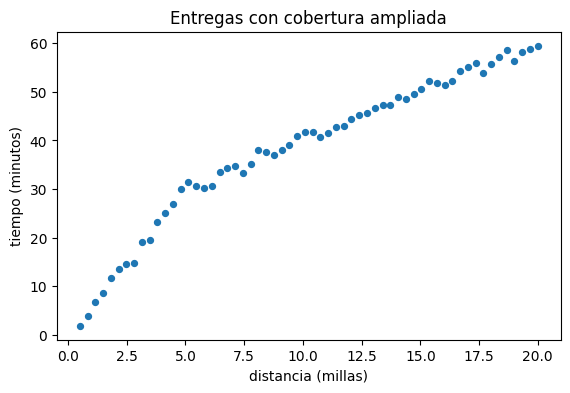

In [11]:
torch.manual_seed(0)

distancias_2 = torch.linspace(0.5, 20, 60).unsqueeze(1)                 # forma [60, 1]

tiempo_real = torch.where(distancias_2 <= 5,
                          6 * distancias_2,                              # centro: 6 min por milla
                          30 + 2 * (distancias_2 - 5))                   # vía rápida: 2 min por milla
tiempos_2 = tiempo_real + torch.randn_like(distancias_2)                # ruido de 1 minuto

plt.figure(figsize=(6.5, 4))
plt.scatter(distancias_2, tiempos_2, s=18)
plt.xlabel("distancia (millas)")
plt.ylabel("tiempo (minutos)")
plt.title("Entregas con cobertura ampliada")
plt.show()

Ahora los puntos forman una línea con un **quiebre**. Una neurona solo sabe dibujar una recta, así que no puede seguir las dos pendientes a la vez. Lo comprobamos enseguida, pero antes hay que preparar los datos.

## 9. Normalizar los datos

Las distancias llegan a 20 y los tiempos a 60. Con números de ese tamaño los gradientes se vuelven grandes y el entrenamiento se vuelve inestable, salvo que se use una tasa de aprendizaje diminuta que lo hace lentísimo. (El porqué exacto se ve en `02-descenso-de-gradiente`.)

La solución habitual es **estandarizar**: restar la media y dividir por la desviación estándar. Así cada variable queda centrada en 0 y con dispersión 1.

$$x_{\text{norm}} = \frac{x - \text{media}}{\text{desviación}}$$

Guardamos la media y la desviación porque hacen falta después: para normalizar una entrada nueva antes de predecir, y para devolver la predicción a minutos.

In [12]:
media_d, desv_d = distancias_2.mean(), distancias_2.std()
media_t, desv_t = tiempos_2.mean(), tiempos_2.std()

X = (distancias_2 - media_d) / desv_d
y = (tiempos_2 - media_t) / desv_t

print(f"distancias: media {media_d:.2f}, desviación {desv_d:.2f}  ->  normalizadas: media {X.mean():.2f}, desviación {X.std():.2f}")
print(f"tiempos   : media {media_t:.2f}, desviación {desv_t:.2f}  ->  normalizados : media {y.mean():.2f}, desviación {y.std():.2f}")

distancias: media 10.25, desviación 5.77  ->  normalizadas: media -0.00, desviación 1.00
tiempos   : media 38.36, desviación 15.37  ->  normalizados : media 0.00, desviación 1.00


El ciclo de entrenamiento es siempre el mismo, así que lo guardamos en una función para reutilizarlo con distintos modelos.

In [13]:
def entrenar(modelo, X, y, lr, epocas):
    """Entrena el modelo con MSE y descenso de gradiente. Devuelve la pérdida de cada época."""
    criterio = nn.MSELoss()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=lr)
    historial = []

    for epoca in range(epocas):
        perdida = criterio(modelo(X), y)

        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

        historial.append(perdida.item())

    return historial

Primero la neurona sola, sobre los datos nuevos:

In [14]:
torch.manual_seed(42)

neurona = nn.Sequential(nn.Linear(1, 1))
historial_neurona = entrenar(neurona, X, y, lr=0.1, epocas=3000)

print(f"Pérdida final de la neurona: {historial_neurona[-1]:.4f}")

Pérdida final de la neurona: 0.0607


## 10. Una red con capa oculta

Para que el modelo pueda doblarse le damos más neuronas, organizadas en capas:

```
distancia  ->  [ 8 neuronas + ReLU ]  ->  [ 1 neurona ]  ->  tiempo
  entrada         capa oculta              capa de salida
```

- **Capa oculta**: 8 neuronas que reciben la distancia. Cada una calcula su propio $w x + b$.
- **ReLU**: la función de activación, que se aplica a la salida de cada neurona oculta. Es simplemente $\text{ReLU}(z) = \max(0, z)$: deja pasar los positivos y convierte los negativos en 0.
- **Capa de salida**: una neurona que combina las 8 salidas en un solo número, el tiempo.

Se llama *oculta* porque sus valores no son ni la entrada ni la salida del modelo: son cálculos intermedios.

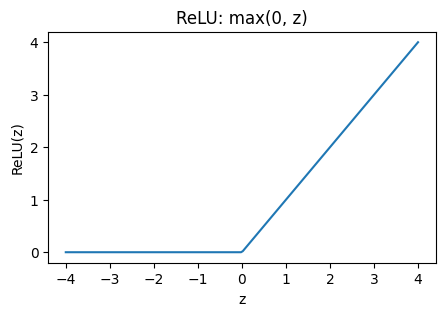

In [15]:
z = torch.linspace(-4, 4, 200)

plt.figure(figsize=(5, 3))
plt.plot(z, torch.relu(z))
plt.xlabel("z")
plt.ylabel("ReLU(z)")
plt.title("ReLU: max(0, z)")
plt.show()

La ReLU es una recta con un quiebre en 0. Cada neurona oculta aporta entonces **una pieza con un quiebre**, ubicado donde su $w x + b$ cambia de signo. La capa de salida suma esas piezas, y el resultado es una línea hecha de tramos rectos que puede doblarse en varios puntos. Justo lo que piden nuestros datos.

En código, pasar de una neurona a una red es agregar capas al `Sequential`:

In [16]:
torch.manual_seed(42)

red = nn.Sequential(
    nn.Linear(1, 8),     # capa oculta: 1 entrada -> 8 neuronas
    nn.ReLU(),           # activación
    nn.Linear(8, 1),     # capa de salida: 8 valores -> 1 predicción
)

print(red)

total = sum(p.numel() for p in red.parameters())
print(f"\nParámetros entrenables: {total}")

Sequential(
  (0): Linear(in_features=1, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)

Parámetros entrenables: 25


El conteo de parámetros sale así:

- Capa oculta: 8 pesos (uno por neurona, porque hay 1 entrada) + 8 sesgos = 16.
- Capa de salida: 8 pesos (uno por cada neurona oculta) + 1 sesgo = 9.

La salida de `nn.Linear(1, 8)` tiene 8 valores y la entrada de `nn.Linear(8, 1)` espera 8. Esos números tienen que coincidir entre capas consecutivas; si no, PyTorch reclama con un error de formas.

La entrenamos con la misma función de antes:

In [17]:
historial_red = entrenar(red, X, y, lr=0.1, epocas=3000)

print(f"Pérdida final de la neurona: {historial_neurona[-1]:.4f}")
print(f"Pérdida final de la red    : {historial_red[-1]:.4f}")

Pérdida final de la neurona: 0.0607
Pérdida final de la red    : 0.0036


La red termina con una pérdida mucho menor. Para ver la diferencia graficamos las dos predicciones en las unidades originales. Como los modelos trabajan con datos normalizados, hay que **deshacer la normalización** de la salida: multiplicar por la desviación y sumar la media de los tiempos.

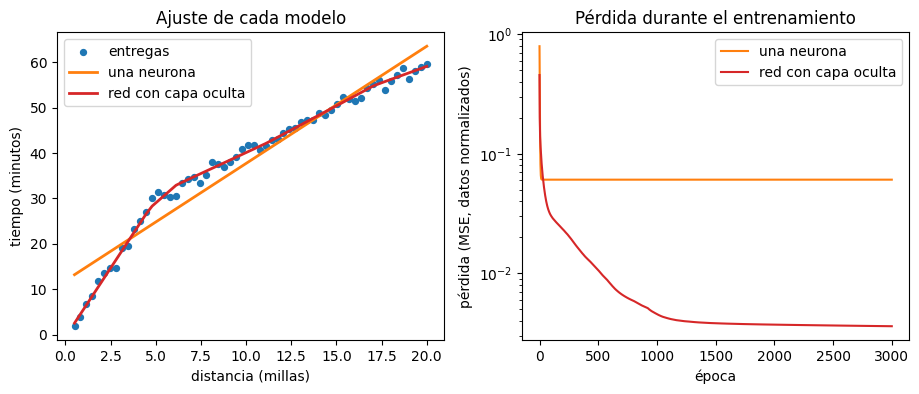

In [18]:
with torch.no_grad():
    pred_neurona = neurona(X) * desv_t + media_t
    pred_red = red(X) * desv_t + media_t

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].scatter(distancias_2, tiempos_2, s=18, label="entregas")
ejes[0].plot(distancias_2, pred_neurona, color="tab:orange", linewidth=2, label="una neurona")
ejes[0].plot(distancias_2, pred_red, color="tab:red", linewidth=2, label="red con capa oculta")
ejes[0].set_xlabel("distancia (millas)")
ejes[0].set_ylabel("tiempo (minutos)")
ejes[0].set_title("Ajuste de cada modelo")
ejes[0].legend()

ejes[1].plot(historial_neurona, color="tab:orange", label="una neurona")
ejes[1].plot(historial_red, color="tab:red", label="red con capa oculta")
ejes[1].set_yscale("log")
ejes[1].set_xlabel("época")
ejes[1].set_ylabel("pérdida (MSE, datos normalizados)")
ejes[1].set_title("Pérdida durante el entrenamiento")
ejes[1].legend()

plt.show()

La neurona traza la mejor recta posible, que queda mal en los dos tramos. La red sigue el quiebre.

Volvemos a la pregunta del pedido, ahora con la red. Para predecir hay que repetir el mismo tratamiento que recibieron los datos de entrenamiento:

1. Normalizar la distancia con la media y desviación **del entrenamiento**.
2. Pasarla por la red.
3. Devolver la salida a minutos.

In [19]:
def predecir_minutos(modelo, millas):
    entrada = (torch.tensor([[millas]]) - media_d) / desv_d      # 1. normalizar
    with torch.no_grad():
        salida = modelo(entrada)                                 # 2. predecir
    return (salida * desv_t + media_t).item()                    # 3. volver a minutos


for millas in [3.0, 7.0, 15.0]:
    real = 6 * millas if millas <= 5 else 30 + 2 * (millas - 5)
    print(f"{millas:4.1f} millas   neurona: {predecir_minutos(neurona, millas):5.1f} min   "
          f"red: {predecir_minutos(red, millas):5.1f} min   regla real: {real:5.1f} min")

 3.0 millas   neurona:  19.7 min   red:  17.7 min   regla real:  18.0 min
 7.0 millas   neurona:  30.0 min   red:  34.6 min   regla real:  34.0 min
15.0 millas   neurona:  50.6 min   red:  50.4 min   regla real:  50.0 min


La columna *regla real* es la fórmula con la que generamos los datos, sin ruido. En un problema de verdad no la conoces; aquí sirve para comprobar que la red se acerca a ella y la neurona no.

## 11. Por qué hace falta la activación

Se podría pensar que lo que ayuda es tener más neuronas y que la ReLU es un detalle. Es al revés: **sin activación, apilar capas no permite representar nada nuevo**.

Si la capa oculta calcula $h = W_1 x + b_1$ y la de salida $\hat{y} = W_2 h + b_2$, al reemplazar queda

$$\hat{y} = W_2 (W_1 x + b_1) + b_2 = \underbrace{(W_2 W_1)}_{w} \, x + \underbrace{(W_2 b_1 + b_2)}_{b}$$

que vuelve a ser una recta. Dos capas lineales seguidas equivalen a una sola. Lo comprobamos con números:

In [20]:
torch.manual_seed(0)

sin_activacion = nn.Sequential(
    nn.Linear(1, 8),
    nn.Linear(8, 1),
)

W1, b1 = sin_activacion[0].weight, sin_activacion[0].bias
W2, b2 = sin_activacion[1].weight, sin_activacion[1].bias

w_equivalente = W2 @ W1                 # un solo número
b_equivalente = W2 @ b1 + b2

with torch.no_grad():
    salida_dos_capas = sin_activacion(X)
    salida_una_recta = X * w_equivalente + b_equivalente

print("w equivalente:", round(w_equivalente.item(), 4))
print("b equivalente:", round(b_equivalente.item(), 4))
print("¿Las dos capas dan lo mismo que esa recta?", torch.allclose(salida_dos_capas, salida_una_recta, atol=1e-6))

w equivalente: 0.6638
b equivalente: -0.1879
¿Las dos capas dan lo mismo que esa recta? True


La activación es lo que rompe esa equivalencia y le permite a la red representar curvas y quiebres. Por eso toda red lleva una función no lineal entre capa y capa.

Para cerrar, miramos dentro de la red entrenada. Graficamos la salida de cada una de las 8 neuronas ocultas (después de la ReLU) según la distancia:

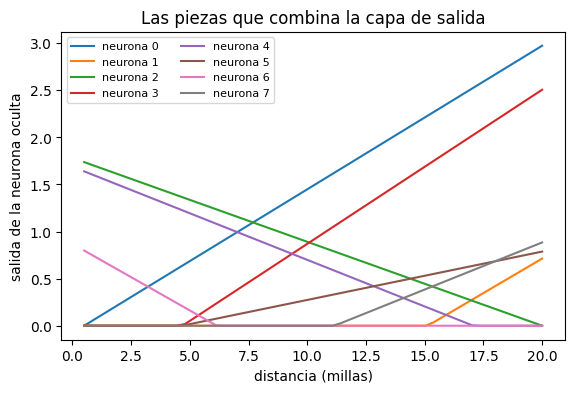

In [21]:
with torch.no_grad():
    ocultas = red[1](red[0](X))          # salida de la capa oculta: forma [60, 8]

plt.figure(figsize=(6.5, 4))
for i in range(ocultas.shape[1]):
    plt.plot(distancias_2, ocultas[:, i], label=f"neurona {i}")
plt.xlabel("distancia (millas)")
plt.ylabel("salida de la neurona oculta")
plt.title("Las piezas que combina la capa de salida")
plt.legend(fontsize=8, ncol=2)
plt.show()

Cada línea es una pieza: plana en 0 mientras la neurona está "apagada" y recta cuando se "enciende". Algunas se encienden hacia la derecha y otras hacia la izquierda, según el signo de su peso. Si una línea es 0 en todo el rango, esa neurona no está aportando nada en estos datos. La predicción final es una suma ponderada de estas ocho piezas más un sesgo.

## 12. Resumen

- El flujo de trabajo es **preparar datos, construir el modelo, entrenar y predecir**.
- Los datos van con forma `[ejemplos, características]` y tipo `float32`.
- `nn.Linear(1, 1)` es una neurona: calcula $w x + b$. Solo puede representar una recta.
- La **función de pérdida** mide el error y el **optimizador** ajusta los parámetros para reducirlo.
- El ciclo de entrenamiento es siempre: predicción, pérdida, `zero_grad()`, `backward()`, `step()`.
- **Normalizar** los datos suele hacer el entrenamiento más estable y más rápido. Lo que le hagas a los datos de entrenamiento hay que repetirlo al predecir.
- Una **capa oculta con activación** permite representar relaciones que no son una recta. Sin activación, varias capas equivalen a una sola.
- Predecir fuera del rango de los datos de entrenamiento es extrapolar, y el modelo no da garantías ahí.

## Ejercicios

1. En la sección 5, entrena con `lr=0.0001` y luego con `lr=0.1`. ¿Qué pasa con la pérdida en cada caso? (La explicación está en el módulo siguiente.)
2. Comenta la línea `optimizador.zero_grad()` del ciclo de la sección 5 y vuelve a entrenar desde cero. ¿Qué observas?
3. En la sección 9, entrena la neurona con los datos **sin normalizar** (`distancias_2` y `tiempos_2`) y `lr=0.1`. ¿Qué valor toma la pérdida? Busca una tasa de aprendizaje con la que funcione.
4. Cambia la capa oculta a 2 neuronas y luego a 32. ¿Cómo cambia la pérdida final? ¿Cuántos parámetros tiene cada versión?
5. Reemplaza `nn.ReLU()` por `nn.Tanh()`. ¿Cómo cambia la forma de la curva ajustada cerca del quiebre?
6. Pídele a la red una predicción para 40 millas. ¿Es confiable? ¿Por qué?